# 36 — Production posterior with measured inlet temperatures (System I, N3, P2)

**Why.** Notebook 34 showed the nominal-inlet production posterior (nb31) is confidently wrong when
the inlet is not nominal (0.5 K on the coolant inlet → β biased by 7–13 posterior sds). Notebook 35
showed that giving the posterior the **measured** inlet temperatures removes that failure, with an
instrument requirement of a calibration error ≤ 0.1 K. **Design decision (user, 2026-11-09):** the
paper's production model measures Ti and Tci with class-AA RTDs (ε = 0.1 K); 0.05 and 0.2 K are
sensitivity results (nb35). The nb31 posterior stays as the *naive* nominal-inlet model (nb34, and
Claim 1 in nb07 at the nominal inlet).

**Design.** Plant and sensors as nb35 (inlet varies ±2 K per window; Ci ±1% unmeasured; measured
Ti, Tci with a 0.1 K calibration offset + averaged sensor noise); 34-D features (29 summaries,
plug-in estimators with the measured inlet, measured Ti, Tci). Bank 160k; budgets 5k–160k; 5 seeds;
test: SBC (1000) + scenario grid (Sc1–Sc5, Sc7 × 50) with the inlet varying.

## Rules — fixed before running
* **Budget and deployed object:** nb31 rule **v2.1**, unchanged (persistent convergence incl. the
  precision criterion; the deployed posterior must itself pass calibration (d)).
* **Acceptance:** on the nb35 inlet grid (true Tci, Ti each ±0.5, ±1, ±2 K; Sc1–Sc4), nb35's
  deployability criteria (β cov90 ≥ 0.80; class accuracy ≥ nb35 oracle − 0.10). At most one
  violating cell, and no v2.1 flag; otherwise **STOP** for the user.

**Running.** ≈ 4–5 h (bank, 30 trainings, evaluation). Re-running resumes.


In [1]:
import json, os, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
import importlib, system_I_config, ws_protocols, ws_eval, ws_metrics, ws_inlet, nb29_ws_study, nb31_budget_convergence, nb35_measured_inlet, nb36_production_measured_inlet
for _m in (system_I_config, ws_protocols, ws_eval, ws_metrics, ws_inlet, nb29_ws_study, nb31_budget_convergence, nb35_measured_inlet, nb36_production_measured_inlet):
    importlib.reload(_m)
P = nb36_production_measured_inlet
assert P.SENSOR == "N3" and P.EPS == 0.1, (P.SENSOR, P.EPS)
R, FIGS = ROOT / "results", ROOT / "figures"
THREADS = 4
T0 = time.time()
print("sensor", P.SENSOR, "| protocol", P.PROTOCOL, "| features", P.FEATURES, "| eps", P.EPS, "K | outputs", P.TAG)

sensor N3 | protocol P2 | features S1m_measured_inlet | eps 0.1 K | outputs 36_N3


## 1. Bank, test set, training (resumable)

In [2]:
P.stage_bank()
P.stage_test()
P.stage_train(THREADS)
print(f"{(time.time() - T0) / 60:.1f} min")

chunk 0: 44s


chunk 1: 43s


chunk 2: 42s


chunk 3: 42s


chunk 4: 43s


chunk 5: 42s


... (39 outputs left out)

40000 4 112 s


80000 4 207 s


160000 4 322 s


73.5 min


## 2. Evaluation across budgets

5000 0 {'ks_p_a_interior': 0.225, 'ks_p_b_interior': 0.0, 'tarp_ks_p': 0.057, 'cov90_b': 0.866}


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


5000 1 {'ks_p_a_interior': 0.002, 'ks_p_b_interior': 0.0, 'tarp_ks_p': 0.002, 'cov90_b': 0.875}


5000 2 {'ks_p_a_interior': 0.858, 'ks_p_b_interior': 0.768, 'tarp_ks_p': 0.5, 'cov90_b': 0.871}


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


5000 3 {'ks_p_a_interior': 0.251, 'ks_p_b_interior': 0.199, 'tarp_ks_p': 0.603, 'cov90_b': 0.867}


... (34 outputs left out)

160000 3 {'ks_p_a_interior': 0.702, 'ks_p_b_interior': 0.635, 'tarp_ks_p': 0.5, 'cov90_b': 0.909}


160000 4 {'ks_p_a_interior': 0.037, 'ks_p_b_interior': 0.163, 'tarp_ks_p': 0.551, 'cov90_b': 0.91}


160000 ensemble {'ks_p_a_interior': 0.124, 'ks_p_b_interior': 0.443, 'tarp_ks_p': 0.71, 'cov90_b': 0.911}


,ks_p_a_interior,ks_p_b_interior,tarp_ks_p,tarp_dev,cov90_a,cov90_b,rmse_norm,macro_f1,sda_Sc1,sdb_Sc1,sda_Sc4,sdb_Sc4,corr_Sc4
budget,,,,,,,,,,,,,
5000,0.0876,0.0078,0.7098,0.021,0.903,0.901,0.0499,0.7967,0.0557,0.0471,0.0475,0.0486,0.1456
10000,0.5542,0.0007,0.3627,0.029,0.921,0.896,0.0494,0.8026,0.0550,0.0439,0.0463,0.0449,0.1465
20000,0.0625,0.0296,0.7098,0.021,0.919,0.905,0.0486,0.8137,0.0559,0.0437,0.0436,0.0435,0.1475
40000,0.0635,0.2754,0.6566,0.021,0.920,0.906,0.0483,0.8178,0.0536,0.0418,0.0420,0.0422,0.1586
80000,0.0131,0.4008,0.7098,0.021,0.921,0.912,0.0482,0.8274,0.0536,0.0411,0.0413,0.0421,0.1460
160000,0.1238,0.4426,0.7098,0.021,0.916,0.911,0.0481,0.8238,0.0541,0.0412,0.0415,0.0411,0.1418


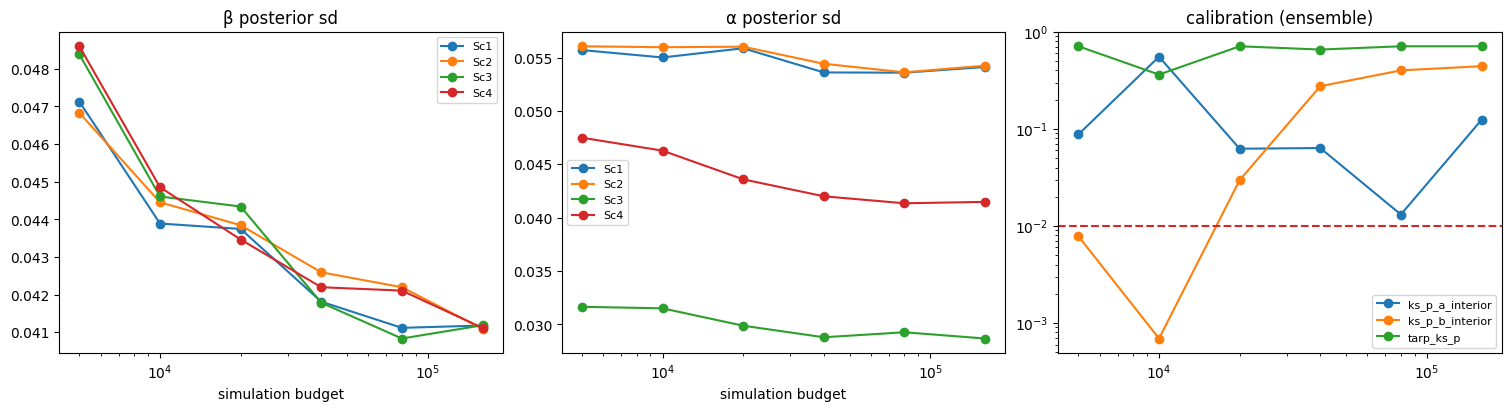

In [3]:
P.stage_eval()
m = pd.read_csv(R / f"{P.TAG}_metrics.csv"); m["member"] = m["member"].astype(str)
ens = m[m.member == "ensemble"].set_index("budget").sort_index()
display(ens[["ks_p_a_interior", "ks_p_b_interior", "tarp_ks_p", "tarp_dev", "cov90_a", "cov90_b", "rmse_norm",
             "macro_f1", "sda_Sc1", "sdb_Sc1", "sda_Sc4", "sdb_Sc4", "corr_Sc4"]].round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for s in ("Sc1", "Sc2", "Sc3", "Sc4"):
    axes[0].plot(ens.index, ens[f"sdb_{s}"], "o-", label=s); axes[1].plot(ens.index, ens[f"sda_{s}"], "o-", label=s)
for ax, t in zip(axes[:2], ("β posterior sd", "α posterior sd")):
    ax.set_xscale("log"); ax.set_xlabel("simulation budget"); ax.set_title(t); ax.legend(fontsize=8)
for k in ("ks_p_a_interior", "ks_p_b_interior", "tarp_ks_p"):
    axes[2].plot(ens.index, ens[k], "o-", label=k)
axes[2].axhline(0.01, color="C3", ls="--"); axes[2].set_xscale("log"); axes[2].set_yscale("log")
axes[2].set_title("calibration (ensemble)"); axes[2].legend(fontsize=8)
fig.savefig(FIGS / f"{P.TAG}_budget_convergence.png", dpi=150); plt.show()

## 3. Production decision (nb31 rule v2.1, unchanged)

In [4]:
res = P.stage_decide()
if res["flag"]:
    raise RuntimeError("STOP: v2.1 decision flagged -- user review: " + str(res["flag"]))

 from     to  a_corr  b_cov  c_tarp  d_calib  e_precision  converged
 5000  10000    True   True    True    False         True      False
10000  20000    True   True    True     True         True       True
20000  40000    True   True    True     True         True       True
40000  80000    True   True    True     True         True       True
80000 160000    True   True    True     True         True       True
production: 20000 ensemble | flag: None


## 4. Acceptance on the nb35 inlet grid, and comparison with the naive nominal-inlet model
The same windows as nb35 (true Tci, Ti each ±0.5, ±1, ±2 K). Reference rows: nb35's oracle and the
nb31 nominal-inlet production posterior on those windows (from `35_N3_metrics.csv`).

In [5]:
acc, acc_res = P.stage_accept()
acc_g = acc[acc.short.isin(["Sc1", "Sc2", "Sc3", "Sc4"])]
for k in ("bias_b", "z_bias_b", "cov90_truth_b", "sd_b", "class_acc"):
    print(k)
    display(acc_g.pivot_table(index="condition", columns="short", values=k).reindex(list(P.M.CONDITIONS)).round(3))
m35 = pd.read_csv(R / "35_N3_metrics.csv"); m35["short"] = m35.scenario.str.split("_").str[0]
ref = m35[m35.variant.isin(["oracle", "eps0.1", "production"]) & m35.short.isin(["Sc1", "Sc2", "Sc3", "Sc4"])]
comp = pd.concat([acc_g.assign(variant="nb36 production (eps 0.1, 160k study)"), ref])
summ = comp.groupby(["variant"]).agg(cov90_b_min=("cov90_truth_b", "min"), cov90_b_mean=("cov90_truth_b", "mean"),
                                     abs_bias_b=("bias_b", lambda v: np.abs(v).mean()), sd_b=("sd_b", "median"),
                                     class_acc=("class_acc", "mean"))
display(summ.round(3))
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")

acceptance: 4 violating cell(s); accepted = False


RuntimeError: STOP: the measured-inlet production posterior fails acceptance -- user decision

## 5. Interpretation (N3 + P2, measured inlet ε = 0.1 K) — written 2026-11-09

*State of this notebook.* The run stopped at the acceptance cell (section 4): the pre-set criterion (at most one violating cell) was missed with 4 of 52 cells, and the notebook raised, as designed. Training, evaluation and the v2.1 decision (sections 1–3) completed. The user then **accepted the posterior with a documented exception, without amending the criterion** (`results/36_N3_acceptance_review.json`, follow-up `results/36_N3_acceptance_followup.csv`, script `logs/36_N3_acceptance_followup.py`). The comparison cell after the stop was not executed; its numbers below come from `36_N3_acceptance.csv` and `35_N3_metrics.csv` (read-only). Since 2026-11-09 the notebook is reproducible: `stage_accept` passes this outcome through the recorded exception (`results/36_N3_acceptance_review.json`, same number and set of violating cells; any other outcome still raises), and the builder keeps this section when it rebuilds.

**Result.** The production model of the paper is a posterior conditioned on **measured inlet temperatures** (class-AA RTDs, ε = 0.1 K): a **20,000-simulation, 5-seed ensemble**, calibrated, with β sd 0.04 and α sd 0.04–0.06, and robust over ±2 K of true inlet error, where the naive nominal-inlet posterior (nb31) collapses. Its cost is class accuracy for faults close to the class threshold: at β = 0.85 (0.05 below the 0.90 threshold) it is 0.07–0.13 below the oracle that knows the inlet exactly; ε = 0.05 K recovers most of that. This is the "reliable if the simulator and the inlet are right" half of the storyline, with the instrument trade-off that decides how much of the diagnosis it keeps.

**1. Budget and calibration (rule v2.1, unchanged, not flagged).** The first persistently converged step is 10k → 20k (largest relative sd change 0.058; max |ΔCorr(α, β)| 0.018); 5k → 10k fails calibration (d) (interior β KS p 0.001 at 10k; 0.008 at 5k), so the budget is **20k, ensemble**. The nuisance does not need more budget than the nominal-inlet model (nb31: 40k; N0: 160k). At 20k the ensemble passes (d) (interior KS p α 0.063, β 0.030, TARP KS p 0.71, TARP deviation 0.021, 90% coverage 0.919 / 0.905); **only 2 of the 5 single members do** (interior β KS p 0.268, 0.704, 0.248, 0.001, 0.000; interior α KS p 0.249, 0.623, 0.000, 0.033, 0.043), so v2.1 once more keeps a miscalibrated seed out of production (the same lesson as nb31: calibration belongs to the ensemble, check it on the deployed object). The ensemble passes TARP at every budget (KS p 0.36–0.71), where notebook 35's 3-seed 40k oracle failed it (KS p 0.0004); I did not test why. From 20k to 160k: interior KS p α 0.013–0.12, β 0.03–0.44, coverage 0.916–0.921 (α), 0.905–0.912 (β), macro-F1 0.81–0.83.

**2. Precision.** Ensemble posterior sd at Sc1 / Sc4: β 0.044 / 0.043 (20k), 0.041 / 0.041 (160k); α 0.056 / 0.044 (20k), 0.054 / 0.041 (160k). On the nominal inlet (1,000 fresh windows): β sd 0.037 (Sc1), 0.045 (Sc2), 0.036 (Sc3), 0.044 (Sc4), against 0.016–0.017 for the oracle (inlet known), 0.024–0.032 for ε = 0.05 K and 0.034–0.044 for the 40k × 3 ε = 0.1 K variant of notebook 35 (the production ensemble is indistinguishable from it). The naive model's 0.015 is valid only if the inlet is the nominal one; the price of not assuming it is a factor of about 3 in β sd and of 1.1 in α sd (α 0.044 against 0.039 at Sc4).

**3. Robustness over ±2 K (the nb35 grid: 13 conditions × Sc1–Sc4).** β 90% coverage min / mean, mean |β bias|, class accuracy: **production 0.84 / 0.937, 0.005, 0.907**; nb35 ε = 0.1 K 0.84 / 0.932, 0.005, 0.912; oracle 0.84 / 0.929, 0.003, 0.932; **naive 0.00 / 0.166, 0.166, 0.610**. For Tci ±2 K: 0.93, 0.004, 0.918 against 0.00, 0.311, 0.448 (naive); Ti ±2 K: 0.94, 0.009, 0.890 against 0.002, 0.204, 0.425. The silent failure of notebook 34 is removed, with a slight conservatism (coverage above 0.90 in most cells).

**4. The accepted exception and the instrument trade-off (follow-up on ~1,000 fresh windows per cell, identical windows for all posteriors).** Class accuracy ± binomial SE / β sd (cells in bold failed acceptance):

| cell | production (ε 0.1, 20k × 5) | nb35 ε 0.1 (40k × 3) | nb35 ε 0.05 | oracle |
|---|---|---|---|---|
| **Sc2 nominal** | 0.877 ± 0.010 / 0.045 | 0.891 / 0.044 | 0.951 / 0.032 | 0.987 / 0.017 |
| **Sc2 Tci −0.5 K** | 0.921 ± 0.009 / 0.040 | 0.915 / 0.039 | 0.976 / 0.027 | 0.994 / 0.015 |
| **Sc2 Tci +0.5 K** | 0.857 ± 0.011 / 0.051 | 0.898 / 0.050 | 0.935 / 0.039 | 0.985 / 0.022 |
| **Sc4 Tci +0.5 K** | 0.803 ± 0.013 / 0.050 | 0.813 / 0.048 | 0.846 / 0.036 | 0.877 / 0.019 |
| Sc4 nominal | 0.810 ± 0.012 / 0.044 | 0.800 / 0.042 | 0.862 / 0.029 | 0.881 / 0.016 |
| Sc1 nominal | 0.984 ± 0.004 / 0.037 | 0.987 | 0.986 | 0.988 |
| Sc3 nominal | 1.000 / 0.036 | 1.000 | 1.000 | 1.000 |

β 90% coverage is 0.94–0.96 in the failing cells (all posteriors 0.91–0.97). The shortfall is **real, not noise**: it is the width of the β posterior at ε = 0.1 K (0.045 against 0.017 for the oracle) acting on a fault 0.05 below the class threshold, where an unbiased posterior of that width classifies about 0.87 correctly (observed 0.877) and the oracle about 0.99 (observed 0.987). Measured against the oracle on the larger sets the production ensemble is 0.110 (Sc2 nominal), 0.073 (Tci −0.5 K), 0.128 (Tci +0.5 K) and 0.074 (Sc4 Tci +0.5 K) below it; with 50 windows per cell the criterion decides on noise only at the margin, but its centre sits at the shortfall the sensor accuracy implies. Healthy and catalyst-decay plants are unaffected (0.98–1.00). **Trade-off for the checklist:** ε = 0.1 K gives a calibrated, robust (±2 K) posterior with β sd 0.04 and fouling accuracy ≈ 0.86–0.92 at β = 0.85 and ≈ 0.80–0.81 at the combined Sc4 point; ε = 0.05 K (a calibrated sensor or a matched pair) raises these to 0.94–0.98 and 0.85–0.86 at β sd 0.03; knowing the inlet exactly gives 0.985–0.994 and 0.88 at β sd 0.017. Fouling that is only slightly beyond the threshold needs a better coolant-inlet measurement than faults that are further away.

**5. For the paper, and follow-ups (not run here).** *Production and naive models.* This posterior is the production model; the headline β and α precision and the diagnosis figures come from here (β ±0.04, α ±0.04–0.06, class accuracy 0.907 over ±2 K, calibrated). The nb31 nominal-inlet posterior is the **naive model** of the silent-failure section (notebooks 34–35: coverage 0.00 and bias up to 0.31 once the inlet is off by 0.5–2 K). **Claim 1 (notebook 07) remains a nominal-inlet comparison**: both the closed-loop and the open-loop posterior assume the nominal inlet; the paper must say so. *Data for the downstream notebooks:* this posterior needs the **measured Ti and Tci of every window** as inputs; `data/observations.npz` of notebook 02 was generated at the nominal inlet and (to be checked) carries no inlet measurement, so Phase-3 evaluations that use it (classification, tracking, baselines) must either regenerate it with the inlet varying and measured, or evaluate the naive model, and say which. *Limitations carried from notebook 35:* no offset on the jacket-outlet sensor, feed flow exact, Ci unmeasured (±1%), inlet range ±2 K, simulated sensors.
